# Grafik deskriptif eval1

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Panel `eval1.do`: residual konstruksi, enam pilar profil, pangsa tenaga kerja, koefisien FGLS grup tersimpan.
--> `pilar_*` = indeks profil eval1: sekolah, logit partisipasi, IPM, −P1, −Gini.
--> Gambar: `01 Data/TFP/output/eval/viz1/`.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
NAVY, CYAN, RED, TEAL, CREAM, PINK, GRAY = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#F2509C", "#797F8C",
)
PULAU_ORDER = ["Sumatera", "Jawa", "Bali-Nusra", "Kalimantan", "Sulawesi", "Maluku-Papua"]
PULAU_FILL = {
    "Sumatera": CREAM, "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PULAU_INK = {
    "Sumatera": "#8A6A32", "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PILAR_COLOR = {
    "pendidikan": NAVY, "equity": TEAL, "institusi": "#062E4C",
    "konektivitas": CYAN, "lingkungan": "#30726A", "keamanan": GRAY,
}
LISA_COLOR = {"HH": NAVY, "HL": CYAN, "LH": CREAM, "LL": RED}
SHORT = {
    11: "Aceh", 12: "Sumut", 13: "Sumbar", 14: "Riau", 15: "Jambi",
    16: "Sumsel", 17: "Bengkulu", 18: "Lampung", 19: "Babel", 21: "Kepri",
    31: "Jakarta", 32: "Jabar", 33: "Jateng", 34: "DIY", 35: "Jatim", 36: "Banten",
    51: "Bali", 52: "NTB", 53: "NTT",
    61: "Kalbar", 62: "Kalteng", 63: "Kalsel", 64: "Kaltim", 65: "Kaltara",
    71: "Sulut", 72: "Sulteng", 73: "Sulsel", 74: "Sultra", 75: "Gorontalo", 76: "Sulbar",
    81: "Maluku", 82: "Malut", 91: "Papua Barat", 94: "Papua",
}
PULAU_OF = {}
for code, pulau in {
    **{c: "Sumatera" for c in [11, 12, 13, 14, 15, 16, 17, 18, 19, 21]},
    **{c: "Jawa" for c in [31, 32, 33, 34, 35, 36]},
    **{c: "Bali-Nusra" for c in [51, 52, 53]},
    **{c: "Kalimantan" for c in [61, 62, 63, 64, 65]},
    **{c: "Sulawesi" for c in [71, 72, 73, 74, 75, 76]},
    **{c: "Maluku-Papua" for c in [81, 82, 91, 94]},
}.items():
    PULAU_OF[code] = pulau
NAME2CODE = {
    "Aceh": 11, "SumateraUtara": 12, "SumateraBarat": 13, "Riau": 14,
    "Jambi": 15, "SumateraSelatan": 16, "Bengkulu": 17, "Lampung": 18,
    "BangkaBelitung": 19, "KepulauanRiau": 21, "JakartaRaya": 31,
    "JawaBarat": 32, "JawaTengah": 33, "Yogyakarta": 34, "JawaTimur": 35,
    "Banten": 36, "Bali": 51, "NusaTenggaraBarat": 52, "NusaTenggaraTimur": 53,
    "KalimantanBarat": 61, "KalimantanTengah": 62, "KalimantanSelatan": 63,
    "KalimantanTimur": 64, "KalimantanUtara": 65, "SulawesiUtara": 71,
    "SulawesiTengah": 72, "SulawesiSelatan": 73, "SulawesiTenggara": 74,
    "Gorontalo": 75, "SulawesiBarat": 76, "Maluku": 81, "MalukuUtara": 82,
    "PapuaBarat": 91, "Papua": 94,
}
# Sisi tak-berarah, daftar eval2.do.
QUEEN_PAIRS = [
    (11, 12), (12, 13), (13, 14), (13, 15), (13, 16), (14, 15), (14, 16), (14, 21),
    (15, 16), (15, 17), (16, 17), (16, 18), (16, 19), (17, 18),
    (31, 32), (31, 36), (32, 33), (32, 36), (33, 34), (33, 35), (35, 51),
    (51, 52), (52, 53),
    (61, 62), (61, 63), (62, 63), (62, 64), (63, 64), (64, 65),
    (71, 72), (71, 75), (71, 82), (72, 73), (72, 74), (72, 75), (72, 76), (73, 74), (73, 76),
    (81, 82), (81, 94), (91, 94),
]
ARCHI_PAIRS = {(14, 21), (16, 19)}  # se-pulau, tetapi dipisah laut
LAB = {
    "z_ln_lama_sekolah_mean": "lama sekolah",
    "z_ln_lama_sekolah_harapan": "harapan sekolah",
    "z_db_sd": "−APK SD", "z_db_smp": "−APK SMP", "z_db_sma": "−APK SMA", "z_db_kampus": "−APK kampus",
    "z_ln_p1": "−kedalaman miskin", "z_ln_ipm": "IPM", "z_gini": "Gini",
    "z_ln_upah_rata": "upah rata-rata", "z_ln_indeks_demokrasi": "IDI",
    "z_price": "−deflator", "z_ln_rasio_pad": "rasio PAD",
    "z_ln_pertumbuhan_pdrb_adhb": "pertumbuhan ADHB", "z_ln_apbd_belanja": "belanja APBD",
    "z_ln_jalan_mantap": "jalan mantap", "z_ln_kargo_udara": "kargo udara",
    "z_ln_kargo_kapal": "kargo kapal", "z_ln_kargo_kereta": "kargo kereta",
    "z_ln_penumpang_total": "penumpang", "z_ln_airport_logistik": "bandara logistik",
    "z_ln_airport_komersil": "bandara komersial",
    "z_ln_indeks_lingkungan": "IKLH", "z_ln_indeks_hijau": "indeks hijau", "z_ln_indeks_biru": "indeks biru",
    "z_ln_crime_risk": "−risiko kriminal", "z_ln_crime_rate": "−crime rate",
    "z_ln_apbd_serapan": "serapan",
    "Wq_pilar_pendidikan": "Wq pendidikan", "Wq_pilar_equity": "Wq equity",
    "Wq_pilar_institusi": "Wq institusi", "Wq_rasio_pad": "Wq rasio PAD",
    "Wq_ln_apbd_belanja": "Wq belanja", "Wi_rasio_pad": "Wi rasio PAD",
    "share_inv_padat_karya": "inv. padat karya", "share_inv_padat_modal": "inv. padat modal",
    "share_inv_primer": "inv. primer", "share_inv_sekunder": "inv. sekunder",
    "share_inv_C": "inv. industri", "share_tk_C": "TK industri",
    "d_dom_primer": "dominan primer", "d_dom_sekunder": "dominan sekunder",
    "share_inv_hijau_inv": "inv. hijau", "share_tk_ekstraktif": "TK ekstraktif",
    "share_inv_A": "inv. pertanian", "d_sawit": "sawit (p75)", "kantong_lemah": "kantong lemah",
}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "medium", "axes.titlecolor": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY,
    "axes.unicode_minus": False, "legend.frameon": False,
})

def save(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    print(path.relative_to(ROOT))
    plt.show()

def star(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

def row_std(A):
    A = np.asarray(A, float)
    s = A.sum(1, keepdims=True)
    s[s == 0] = 1.0
    return A / s

def moran_I(y, W):
    z = np.asarray(y, float)
    z = z - np.nanmean(z)
    den = float(z @ z)
    if den <= 0:
        return np.nan
    return float(z @ (W @ z) / den)

def moran_p(y, W, nperm=999, seed=11):
    rng = np.random.default_rng(seed)
    y = np.asarray(y, float)
    I0 = moran_I(y, W)
    hits = 0
    for _ in range(nperm):
        if abs(moran_I(rng.permutation(y), W)) >= abs(I0) - 1e-15:
            hits += 1
    return I0, (hits + 1) / (nperm + 1)

def edge_style(a, b):
    pair = tuple(sorted((int(a), int(b))))
    if PULAU_OF[pair[0]] != PULAU_OF[pair[1]]:
        return RED, "-"
    if pair in ARCHI_PAIRS:
        return "#8A6A32", "--"
    return NAVY, "-"

def ordered_codes():
    return [c for p in PULAU_ORDER for c in SHORT if PULAU_OF[c] == p]

def weights(codes):
    n = len(codes)
    idx = {c: i for i, c in enumerate(codes)}
    A = np.zeros((n, n))
    for a, b in QUEEN_PAIRS:
        i, j = idx[a], idx[b]
        A[i, j] = A[j, i] = 1.0
    Ai = np.zeros((n, n))
    for i, ci in enumerate(codes):
        for j, cj in enumerate(codes):
            if i != j and PULAU_OF[ci] == PULAU_OF[cj]:
                Ai[i, j] = 1.0
    return A, Ai, row_std(A), row_std(Ai)

def load_gdf(codes):
    import geopandas as gpd
    gadm = ROOT / "02 Code" / "TFP" / "docs" / "06 Review" / "assets" / "gadm41_IDN_1.json"
    g = gpd.read_file(gadm)[["NAME_1", "geometry"]]
    g["Code_Prov"] = g["NAME_1"].map(NAME2CODE)
    g = g.dropna(subset=["Code_Prov"])
    g["Code_Prov"] = g["Code_Prov"].astype(int)
    g = g.dissolve(by="Code_Prov", as_index=False)
    g = g.set_index("Code_Prov").reindex(codes).reset_index()
    if g["geometry"].isna().any():
        raise RuntimeError("GADM tidak memuat semua kode provinsi 34")
    g = g.to_crs(3857)
    g["geometry"] = g.geometry.simplify(2000, preserve_topology=True)
    g["Pulau"] = g["Code_Prov"].map(PULAU_OF)
    g["short"] = g["Code_Prov"].map(SHORT)
    return g

def choro(ax, gdf, col, title, center="zero"):
    s = gdf[col].astype(float)
    if center == "zero":
        v = np.nanmax(np.abs(s.to_numpy()))
        v = 1e-6 if not np.isfinite(v) or v == 0 else float(v)
        norm = mcolors.TwoSlopeNorm(vcenter=0, vmin=-v, vmax=v)
        cmap = "RdBu_r"
    elif center == "mean":
        mu = float(np.nanmean(s))
        v = max(mu - float(np.nanmin(s)), float(np.nanmax(s)) - mu, 1e-6)
        norm = mcolors.TwoSlopeNorm(vcenter=mu, vmin=mu - v, vmax=mu + v)
        cmap = "RdBu_r"
    else:
        norm = mcolors.Normalize(vmin=float(np.nanmin(s)), vmax=float(np.nanmax(s)))
        cmap = "PuBu"
    gdf.plot(column=col, ax=ax, cmap=cmap, norm=norm, linewidth=0.3,
             edgecolor="white", missing_kwds={"color": "#eeeeee"})
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cb = ax.figure.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
    cb.ax.tick_params(labelsize=7)
    ax.set_axis_off()
    ax.set_title(title, fontsize=11)
    ax.set_facecolor("#f6f5f2")

def style_map(ax):
    ax.set_axis_off()
    ax.set_facecolor("#f6f5f2")
    ax.grid(False)

def lisa_labels(y, wy):
    my, mw = np.median(y), np.median(wy)
    out = np.empty(len(y), dtype=object)
    for i, (a, b) in enumerate(zip(y, wy)):
        if a >= my and b >= mw:
            out[i] = "HH"
        elif a < my and b < mw:
            out[i] = "LL"
        elif a >= my and b < mw:
            out[i] = "HL"
        else:
            out[i] = "LH"
    return out

def draw_queen(ax, gdf, title):
    gdf.plot(ax=ax, color="#f4f1ea", edgecolor="white", linewidth=0.45)
    pts = gdf.set_index("Code_Prov").geometry.representative_point()
    for a, b in QUEEN_PAIRS:
        color, ls = edge_style(a, b)
        ax.plot([pts[a].x, pts[b].x], [pts[a].y, pts[b].y],
                color=color, ls=ls, lw=1.15, zorder=3, solid_capstyle="round")
    style_map(ax)
    ax.set_title(title)
    ax.legend(handles=[
        Line2D([0], [0], color=NAVY, lw=1.4, label="queen, darat"),
        Line2D([0], [0], color="#8A6A32", lw=1.4, ls="--", label="queen, laut se-pulau"),
        Line2D([0], [0], color=RED, lw=1.4, label="queen, antar-pulau"),
    ], loc="lower left", fontsize=8)

def draw_islands(ax, gdf, title):
    for p in PULAU_ORDER:
        gdf[gdf.Pulau == p].plot(ax=ax, color=PULAU_FILL[p], edgecolor="white", linewidth=0.45)
    style_map(ax)
    ax.set_title(title)
    ax.legend(handles=[Patch(facecolor=PULAU_FILL[p], edgecolor=GRAY, label=p) for p in PULAU_ORDER],
              loc="lower left", fontsize=8)

def block_lines(ax, codes):
    cuts = []
    start = 0
    for p in PULAU_ORDER:
        k = sum(PULAU_OF[c] == p for c in codes)
        cuts.append(start + k)
        start += k
    for c in cuts[:-1]:
        ax.axhline(c - 0.5, color=RED, lw=0.6)
        ax.axvline(c - 0.5, color=RED, lw=0.6)

OUT = ROOT / "01 Data" / "TFP" / "output" / "eval" / "viz1"
OUT.mkdir(parents=True, exist_ok=True)
PILAR = ["pilar_pendidikan", "pilar_equity", "pilar_institusi",
         "pilar_konektivitas", "pilar_lingkungan", "pilar_keamanan"]
PILAR_LAB = {
    "pilar_pendidikan": "Pendidikan", "pilar_equity": "Equity",
    "pilar_institusi": "Institusi", "pilar_konektivitas": "Konektivitas",
    "pilar_lingkungan": "Lingkungan", "pilar_keamanan": "Keamanan",
}
ev = pd.read_excel(ROOT / "01 Data" / "TFP" / "output" / "eval" / "eval_panel_2017_2025.xlsx")
ev["Code_Prov"] = ev["Code_Prov"].astype(int)
ev["Year"] = ev["Year"].astype(int)
ev["Pulau"] = ev["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
coef = pd.read_csv(ROOT / "01 Data" / "TFP" / "output" / "eval" / "eval1_coef.csv")
pm = ev.drop_duplicates("Code_Prov").copy()
codes = ordered_codes()
gdf = load_gdf(codes)
print(f"{ev.Code_Prov.nunique()} provinsi, {ev.Year.min()}–{ev.Year.max()}, N = {len(ev)}")


34 provinsi, 2017–2025, N = 306


## Jalur, profil pulau, komposisi tenaga kerja


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
01 Data/TFP/output/eval/viz1/ev1_jalur_residual.png
01 Data/TFP/output/eval/viz1/ev1_jalur_pilar.png
01 Data/TFP/output/eval/viz1/ev1_pilar_pulau.png
01 Data/TFP/output/eval/viz1/ev1_heatmap_pilar.png
08_eval1_grafik.ipynb:3:63: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
01 Data/TFP/output/eval/viz1/ev1_komposisi_tk.png


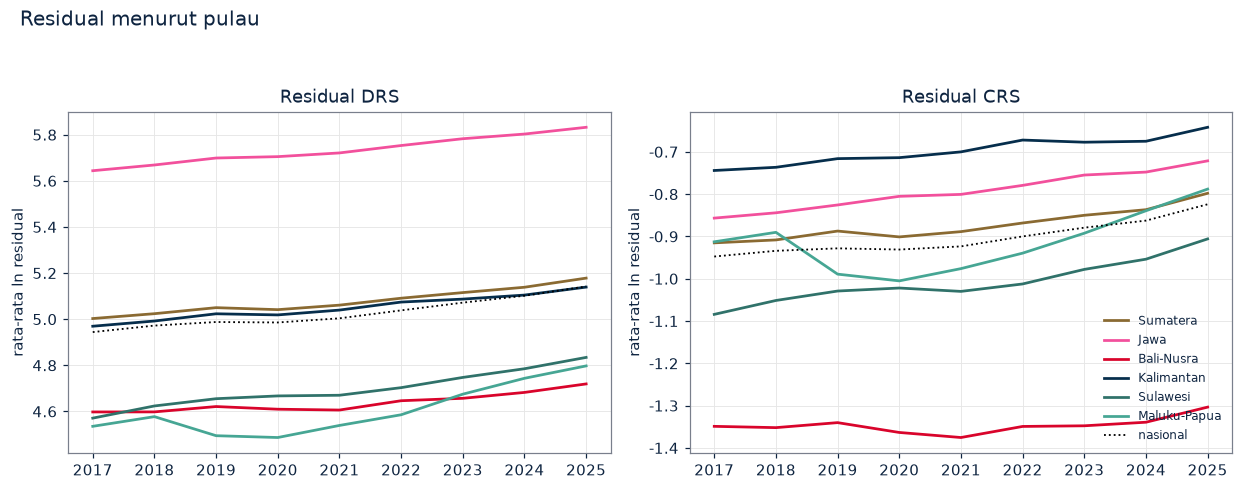

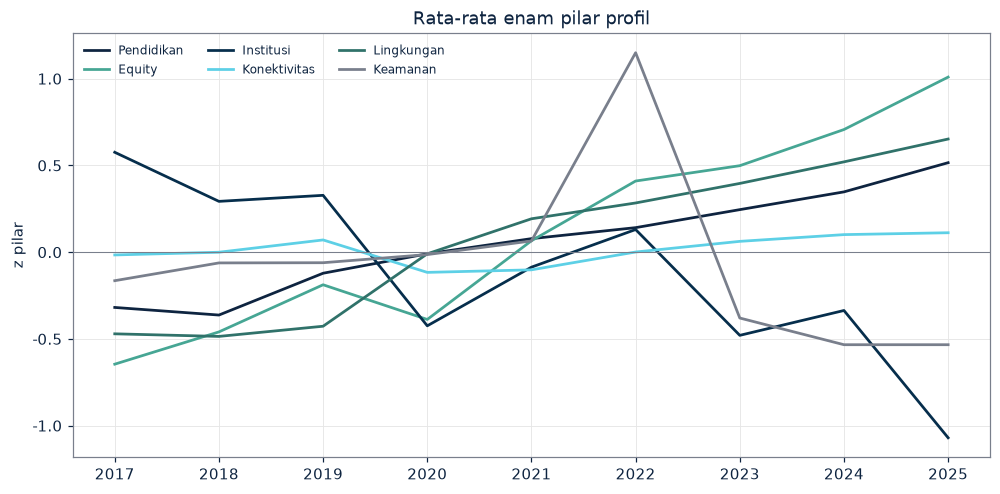

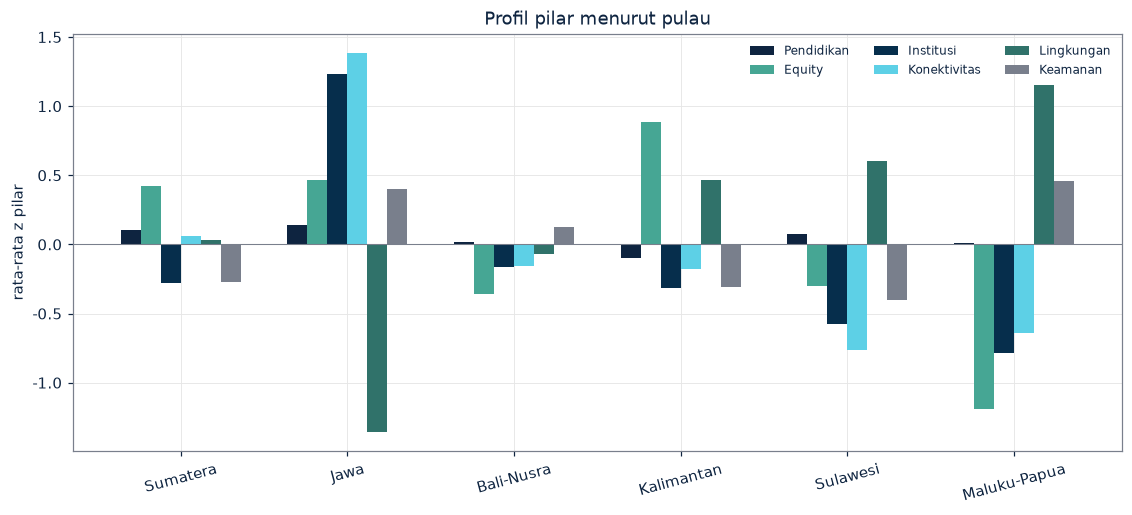

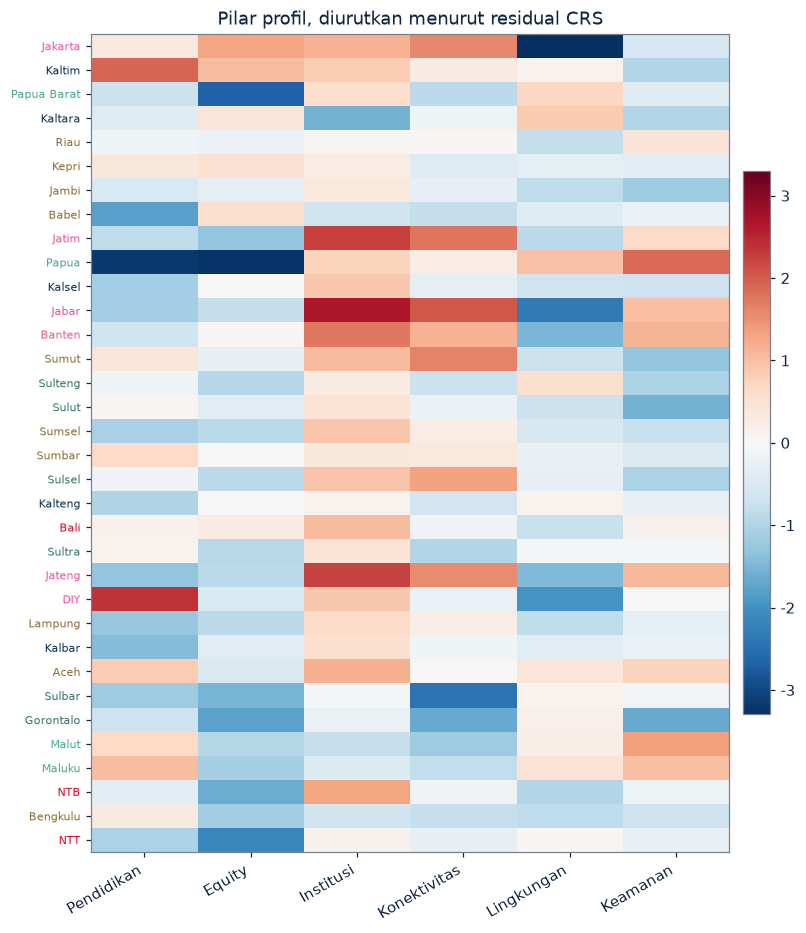

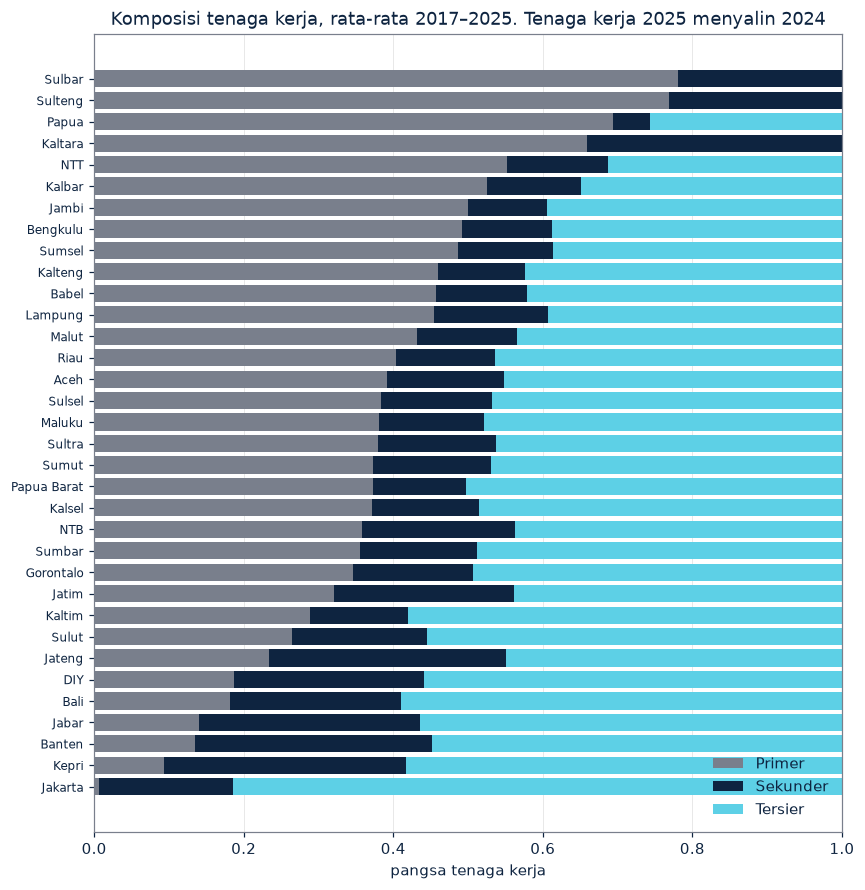

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.5))
for ax, col, title in zip(axes, ["logtfp_it", "logtfp_it_crs"], ["Residual DRS", "Residual CRS"]):
    for p in PULAU_ORDER:
        s = ev[ev.Pulau == p].groupby("Year")[col].mean()
        ax.plot(s.index, s.values, color=PULAU_INK[p], lw=1.8, label=p)
    nat = ev.groupby("Year")[col].mean()
    ax.plot(nat.index, nat.values, color="black", lw=1.2, ls=":", label="nasional")
    ax.set_title(title)
    ax.set_ylabel("rata-rata ln residual")
axes[1].legend(fontsize=8)
fig.suptitle("Residual menurut pulau", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "ev1_jalur_residual.png")

fig, ax = plt.subplots(figsize=(9.2, 4.6))
for col in PILAR:
    s = ev.groupby("Year")[col].mean()
    key = col.replace("pilar_", "")
    ax.plot(s.index, s.values, color=PILAR_COLOR[key], lw=1.8, label=PILAR_LAB[col])
ax.axhline(0, color=GRAY, lw=0.7)
ax.legend(ncol=3, fontsize=8)
ax.set_title("Rata-rata enam pilar profil")
ax.set_ylabel("z pilar")
fig.tight_layout()
save(fig, "ev1_jalur_pilar.png")

isl = ev.groupby("Pulau")[PILAR].mean().reindex(PULAU_ORDER)
fig, ax = plt.subplots(figsize=(10.4, 4.8))
x = np.arange(len(PULAU_ORDER))
width = 0.12
for i, col in enumerate(PILAR):
    key = col.replace("pilar_", "")
    ax.bar(x + (i - 2.5) * width, isl[col], width=width,
           color=PILAR_COLOR[key], label=PILAR_LAB[col])
ax.axhline(0, color=GRAY, lw=0.7)
ax.set_xticks(x)
ax.set_xticklabels(PULAU_ORDER, rotation=15)
ax.set_ylabel("rata-rata z pilar")
ax.set_title("Profil pilar menurut pulau")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
save(fig, "ev1_pilar_pulau.png")

heat = pm.set_index("Code_Prov")[PILAR + ["m_logtfp_it_crs"]]
heat = heat.loc[heat["m_logtfp_it_crs"].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.4, 8.6))
mat = heat[PILAR].to_numpy()
v = np.nanmax(np.abs(mat))
im = ax.imshow(mat, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto", origin="upper")
ax.set_xticks(range(6))
ax.set_xticklabels([PILAR_LAB[c] for c in PILAR], rotation=30, ha="right")
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([SHORT[c] for c in heat.index], fontsize=7)
for lab, c in zip(ax.get_yticklabels(), heat.index):
    lab.set_color(PULAU_INK[PULAU_OF[int(c)]])
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
ax.set_title("Pilar profil, diurutkan menurut residual CRS")
ax.grid(False)
fig.tight_layout()
save(fig, "ev1_heatmap_pilar.png")

comp = pm.set_index("Code_Prov")[["share_tk_primer", "share_tk_sekunder", "share_tk_tersier"]].copy()
comp = comp.div(comp.sum(1), axis=0).sort_values("share_tk_primer", ascending=True)
fig, ax = plt.subplots(figsize=(8, 8.2))
left = np.zeros(len(comp))
for col, color, lab in [
    ("share_tk_primer", GRAY, "Primer"),
    ("share_tk_sekunder", NAVY, "Sekunder"),
    ("share_tk_tersier", CYAN, "Tersier"),
]:
    ax.barh(range(len(comp)), comp[col], left=left, color=color, label=lab, height=0.8)
    left = left + comp[col].to_numpy()
ax.set_yticks(range(len(comp)))
ax.set_yticklabels([SHORT[c] for c in comp.index], fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel("pangsa tenaga kerja")
ax.set_title("Komposisi tenaga kerja, rata-rata 2017–2025. Tenaga kerja 2025 menyalin 2024")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "ev1_komposisi_tk.png")


## Kaitan antar-provinsi dan ujung pilar

Titik = rata-rata provinsi. Garis hanya pemandu mata.


01 Data/TFP/output/eval/viz1/ev1_scatter_crs.png
01 Data/TFP/output/eval/viz1/ev1_skala_KL.png
01 Data/TFP/output/eval/viz1/ev1_topbot.png


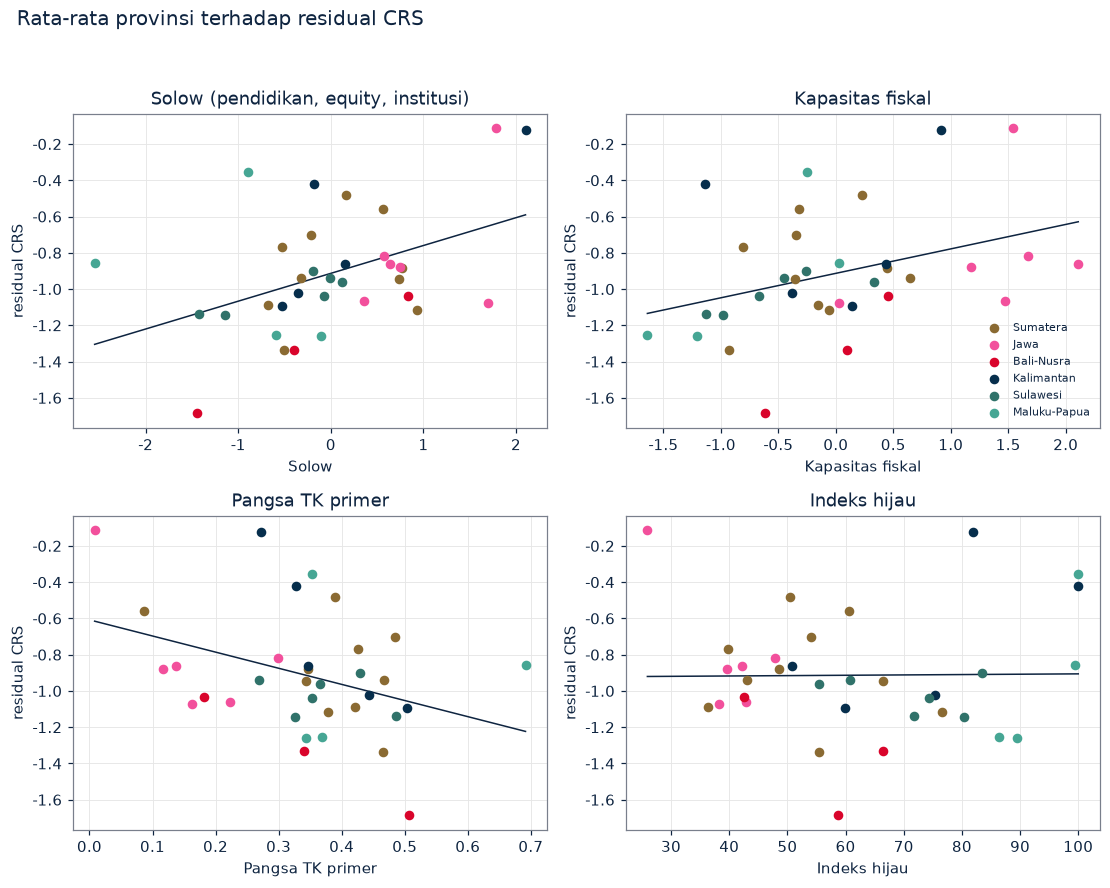

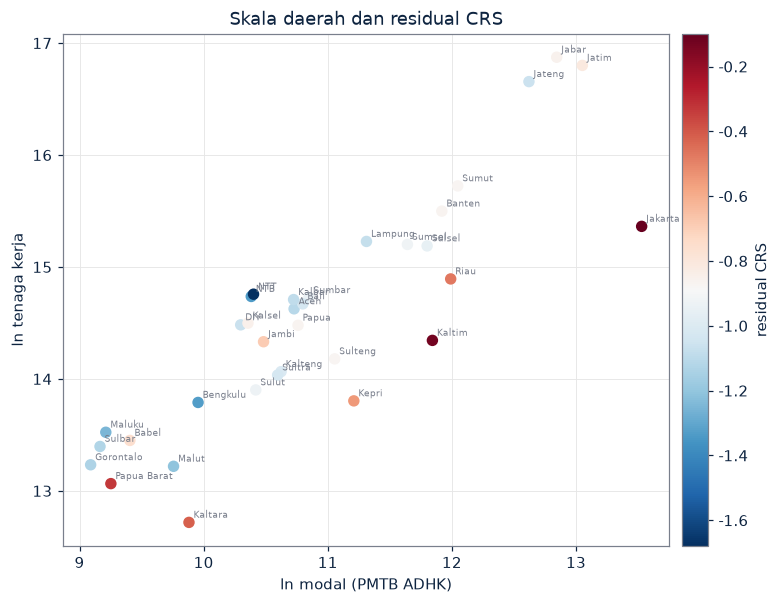

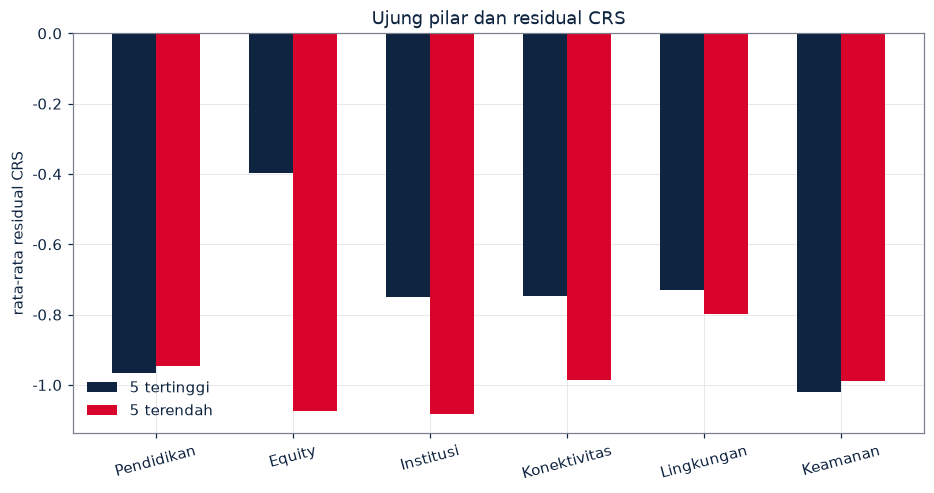

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10.2, 8.2))
pairs = [
    ("m_idx_solow", "Solow (pendidikan, equity, institusi)"),
    ("m_idx_fiskal", "Kapasitas fiskal"),
    ("m_share_tk_primer", "Pangsa TK primer"),
    ("m_indeks_hijau", "Indeks hijau"),
]
ycol = "m_logtfp_it_crs"
for ax, (xcol, title) in zip(axes.ravel(), pairs):
    for p in PULAU_ORDER:
        sub = pm[pm.Pulau == p]
        ax.scatter(sub[xcol], sub[ycol], s=28, color=PULAU_INK[p], label=p, zorder=3)
    x = pm[xcol].to_numpy()
    y = pm[ycol].to_numpy()
    b1, b0 = np.polyfit(x, y, 1)
    xs = np.linspace(np.nanmin(x), np.nanmax(x), 40)
    ax.plot(xs, b0 + b1 * xs, color=NAVY, lw=1)
    r = np.corrcoef(x, y)[0, 1]
    ax.set_title(title)
    ax.set_xlabel(title.split("(")[0].strip())
    ax.set_ylabel("residual CRS")
axes[0, 1].legend(fontsize=7)
fig.suptitle("Rata-rata provinsi terhadap residual CRS", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev1_scatter_crs.png")

kl = ev.groupby(["Code_Prov", "Pulau"], as_index=False)[["log_K", "log_L", "logtfp_it_crs"]].mean()
fig, ax = plt.subplots(figsize=(7.2, 5.6))
sc = ax.scatter(kl["log_K"], kl["log_L"], c=kl["logtfp_it_crs"], cmap="RdBu_r", s=42, zorder=3)
for _, r in kl.iterrows():
    ax.annotate(SHORT[int(r.Code_Prov)], (r.log_K, r.log_L), fontsize=6, color=GRAY, xytext=(3, 3),
                textcoords="offset points")
fig.colorbar(sc, ax=ax, fraction=0.045, pad=0.02).set_label("residual CRS")
ax.set_xlabel("ln modal (PMTB ADHK)")
ax.set_ylabel("ln tenaga kerja")
ax.set_title("Skala daerah dan residual CRS")
fig.tight_layout()
save(fig, "ev1_skala_KL.png")

fig, ax = plt.subplots(figsize=(8.6, 4.6))
x = np.arange(len(PILAR))
top, bot = [], []
for col in PILAR:
    key = col.replace("pilar_", "")
    top.append(pm.loc[pm[f"top5_{key}"] == 1, "m_logtfp_it_crs"].mean())
    bot.append(pm.loc[pm[f"bot5_{key}"] == 1, "m_logtfp_it_crs"].mean())
ax.bar(x - 0.16, top, width=0.32, color=NAVY, label="5 tertinggi")
ax.bar(x + 0.16, bot, width=0.32, color=RED, label="5 terendah")
ax.set_xticks(x)
ax.set_xticklabels([PILAR_LAB[c] for c in PILAR], rotation=15)
ax.set_ylabel("rata-rata residual CRS")
ax.set_title("Ujung pilar dan residual CRS")
ax.legend()
fig.tight_layout()
save(fig, "ev1_topbot.png")


## Koefisien FGLS grup
--> Titik penuh = p < 0.05.
--> Garis = interval 95% dari standar error yang tersimpan.
--> Jumlah koefisien menjumlahkan seluruh z di grup.


01 Data/TFP/output/eval/viz1/ev1_forest_fgls.png
01 Data/TFP/output/eval/viz1/ev1_jumlah_koef.png


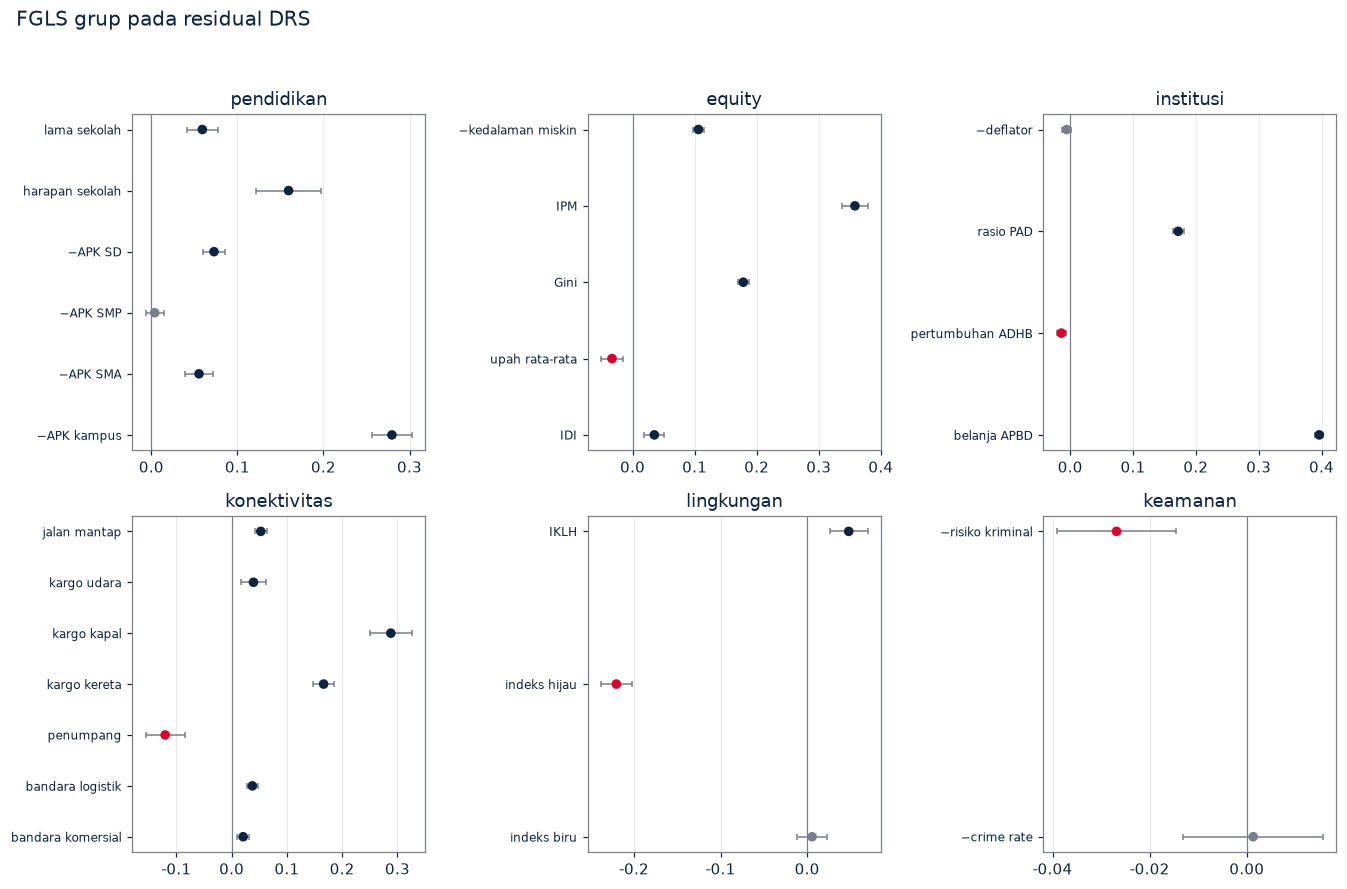

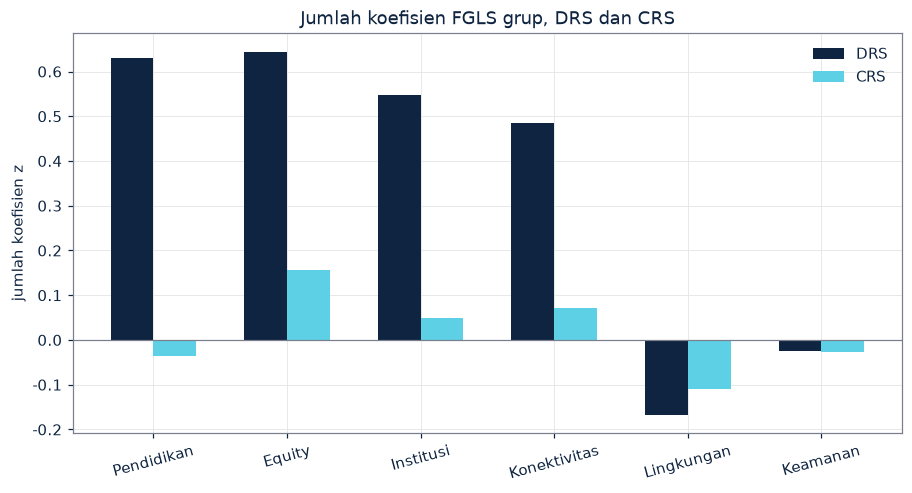

In [4]:
grup = ["pendidikan", "equity", "institusi", "konektivitas", "lingkungan", "keamanan"]

def forest_model(ax, model):
    sub = coef[coef.model == model].copy()
    sub = sub.iloc[::-1]
    y = np.arange(len(sub))
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.errorbar(sub["b"], y, xerr=1.96 * sub["se"], fmt="none", ecolor=GRAY, elinewidth=1, capsize=2)
    colors = [NAVY if (b > 0 and p < 0.05) else RED if (b < 0 and p < 0.05) else GRAY
              for b, p in zip(sub["b"], sub["p"])]
    ax.scatter(sub["b"], y, c=colors, s=28, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([LAB.get(v, v) for v in sub["var"]], fontsize=8)
    ax.set_title(model.replace("FGLS_", ""))
    ax.grid(axis="y")

fig, axes = plt.subplots(2, 3, figsize=(12.4, 8.2))
for ax, g in zip(axes.ravel(), grup):
    forest_model(ax, f"FGLS_{g}")
fig.suptitle("FGLS grup pada residual DRS", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev1_forest_fgls.png")

fig, ax = plt.subplots(figsize=(8.4, 4.6))
x = np.arange(len(grup))
for shift, prefix, color, lab in [(-0.16, "FGLS_", NAVY, "DRS"), (0.16, "FGLS_crs_", CYAN, "CRS")]:
    sums = [coef.loc[coef.model == f"{prefix}{g}", "b"].sum() for g in grup]
    ax.bar(x + shift, sums, width=0.32, color=color, label=lab)
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([g.capitalize() for g in grup], rotation=15)
ax.set_ylabel("jumlah koefisien z")
ax.set_title("Jumlah koefisien FGLS grup, DRS dan CRS")
ax.legend()
fig.tight_layout()
save(fig, "ev1_jumlah_koef.png")


## Peta profil

Warna pilar berpusat di nol. Residual berpusat di rata-rata antar-provinsi.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
01 Data/TFP/output/eval/viz1/ev1_peta_profil.png


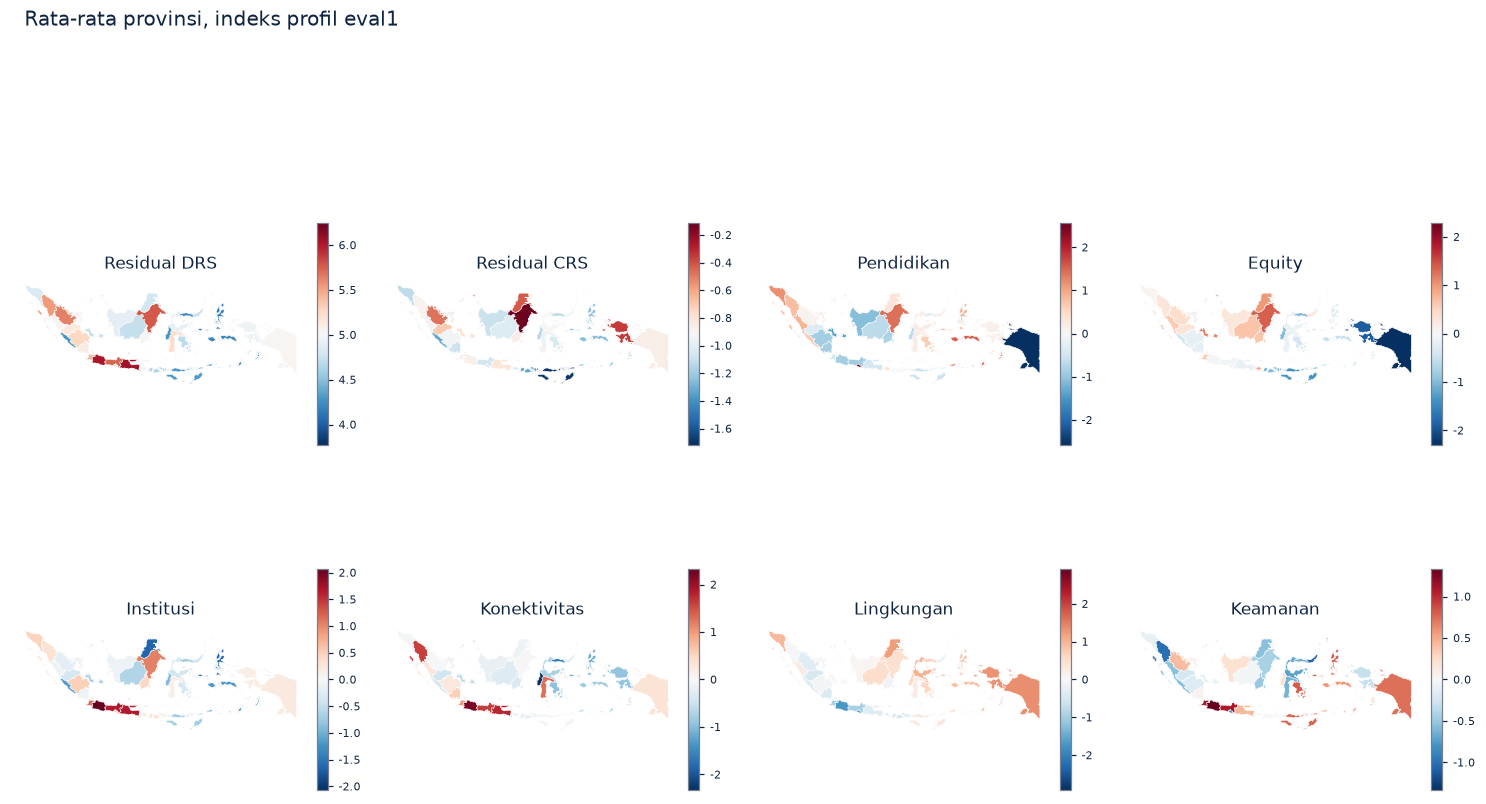

In [5]:
for col, src in {
    "logtfp_it": "m_logtfp_it",
    "logtfp_it_crs": "m_logtfp_it_crs",
    **{c: "m_" + c for c in PILAR},
}.items():
    gdf[col] = gdf["Code_Prov"].map(pm.set_index("Code_Prov")[src])

fig, axes = plt.subplots(2, 4, figsize=(13.6, 8.6))
specs = [("logtfp_it", "Residual DRS", "mean"), ("logtfp_it_crs", "Residual CRS", "mean")]
specs += [(c, PILAR_LAB[c], "zero") for c in PILAR]
for ax, (col, title, center) in zip(axes.ravel(), specs):
    choro(ax, gdf, col, title, center=center)
fig.suptitle("Rata-rata provinsi, indeks profil eval1", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "ev1_peta_profil.png")
